# ***PREDICTING FUTURE OUTCOMES USING PYTHON AND R***

## ***1: LINEAR REGRESSION USING PYTHON***

### ***PREPARE YOUR WORKSTATION AND CLEAN THE DATA***

In [1]:
# IMPORT ALL THE NECESSARY PACKAGES.

import pandas as pd
import numpy as np
import statsmodels.api as sm
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets
from sklearn import linear_model
from sklearn import metrics
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression

In [2]:
# IMPORT AND SENSE CHECK THE turtle_reviews.csv DATASET AS REVIEWS.

reviews = pd.read_csv('turtle_reviews.csv')

# SENSE CHECK THE DATASET.

reviews.head()

,gender,age,remuneration (k£),spending_score (1-100),loyalty_points,education,language,platform,product,review,summary
0,Male,18,12.30,39,210,graduate,EN,Web,453,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,Male,23,12.30,81,524,graduate,EN,Web,466,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,Female,22,13.12,6,40,graduate,EN,Web,254,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Female,25,13.12,77,562,graduate,EN,Web,263,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,Female,33,13.94,40,366,graduate,EN,Web,291,As my review of GF9's previous screens these w...,Money trap


In [3]:
# DETERMINE WHETHER THERE ARE ANY MISSING VALUES.

reviews_na = reviews[reviews.isna().any(axis=1)]
reviews_na.shape

(0, 11)

In [4]:
# DETERMINE THE METADATA  AND THE DESCRIPTIVE STATISTICS OF THE DATASET.

reviews.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   gender                  2000 non-null   object 
 1   age                     2000 non-null   int64  
 2   remuneration (k£)       2000 non-null   float64
 3   spending_score (1-100)  2000 non-null   int64  
 4   loyalty_points          2000 non-null   int64  
 5   education               2000 non-null   object 
 6   language                2000 non-null   object 
 7   platform                2000 non-null   object 
 8   product                 2000 non-null   int64  
 9   review                  2000 non-null   object 
 10  summary                 2000 non-null   object 
dtypes: float64(1), int64(4), object(6)
memory usage: 172.0+ KB


In [5]:
reviews.describe()

,age,remuneration (k£),spending_score (1-100),loyalty_points,product
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,39.495000,48.079060,50.000000,1578.032000,4320.521500
std,13.573212,23.123984,26.094702,1283.239705,3148.938839
min,17.000000,12.300000,1.000000,25.000000,107.000000
25%,29.000000,30.340000,32.000000,772.000000,1589.250000
50%,38.000000,47.150000,50.000000,1276.000000,3624.000000
75%,49.000000,63.960000,73.000000,1751.250000,6654.000000
max,72.000000,112.340000,99.000000,6847.000000,11086.000000


In [6]:
# REMOVE REDUNDANT COLUMNS.

reviews_dr = reviews.drop(columns=['language' , 'platform'])
reviews_dr.head()

,gender,age,remuneration (k£),spending_score (1-100),loyalty_points,education,product,review,summary
0,Male,18,12.30,39,210,graduate,453,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,Male,23,12.30,81,524,graduate,466,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,Female,22,13.12,6,40,graduate,254,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Female,25,13.12,77,562,graduate,263,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,Female,33,13.94,40,366,graduate,291,As my review of GF9's previous screens these w...,Money trap


In [7]:
reviews_trl = reviews_dr.rename(columns={'remuneration (k£)': 'remuneration' , 'spending_score (1-100)': 'spending_score'})

In [8]:
reviews_trl.head()

,gender,age,remuneration,spending_score,loyalty_points,education,product,review,summary
0,Male,18,12.30,39,210,graduate,453,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,Male,23,12.30,81,524,graduate,466,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,Female,22,13.12,6,40,graduate,254,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Female,25,13.12,77,562,graduate,263,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,Female,33,13.94,40,366,graduate,291,As my review of GF9's previous screens these w...,Money trap


### ***SAVE THE CLEANED DATAFRAME AS A CSV FILE***

In [9]:
reviews_trl.to_csv('cleaned_turtle_reviews.csv' , index=False)

### ***IMPORT THE CLEANED DATA CSV FILE AND SENSE CHECK IT***

In [10]:
tr = pd.read_csv('cleaned_turtle_reviews.csv')
tr.head()

,gender,age,remuneration,spending_score,loyalty_points,education,product,review,summary
0,Male,18,12.30,39,210,graduate,453,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,Male,23,12.30,81,524,graduate,466,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,Female,22,13.12,6,40,graduate,254,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Female,25,13.12,77,562,graduate,263,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,Female,33,13.94,40,366,graduate,291,As my review of GF9's previous screens these w...,Money trap


In [11]:
# DETERMINE THE METADATA AND THE DESCRIPTIVE STATISTICS OF THE CLEANED DATAFRAME.

tr.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   gender          2000 non-null   object 
 1   age             2000 non-null   int64  
 2   remuneration    2000 non-null   float64
 3   spending_score  2000 non-null   int64  
 4   loyalty_points  2000 non-null   int64  
 5   education       2000 non-null   object 
 6   product         2000 non-null   int64  
 7   review          2000 non-null   object 
 8   summary         2000 non-null   object 
dtypes: float64(1), int64(4), object(4)
memory usage: 140.8+ KB


In [12]:
tr.describe()

,age,remuneration,spending_score,loyalty_points,product
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,39.495000,48.079060,50.000000,1578.032000,4320.521500
std,13.573212,23.123984,26.094702,1283.239705,3148.938839
min,17.000000,12.300000,1.000000,25.000000,107.000000
25%,29.000000,30.340000,32.000000,772.000000,1589.250000
50%,38.000000,47.150000,50.000000,1276.000000,3624.000000
75%,49.000000,63.960000,73.000000,1751.250000,6654.000000
max,72.000000,112.340000,99.000000,6847.000000,11086.000000


### ***LINEAR REGRESSION***

### ***SPENDING VS LOYALTY***

In [13]:
# DEFINE THE DEPENDENT VARIABLE.
y = tr['loyalty_points'].values.reshape(-1,1)

# DEFINE THE INDEPENDENT VARIABLE.
x = tr['spending_score'].values.reshape(-1,1)

# FIT THE MODEL.
lt = LinearRegression()
lt.fit(x,y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [14]:
# SPLIT THE DATA INTO TRAINING = 0.7 AND TESTING = 0.3 SUBSETS.
x_train, x_test, y_train, y_test = train_test_split(x, y,\
                                                    train_size = 0.7,\
                                                    random_state = 42)

# FIT THE MODEL ONCE AGAIN WITH TRAIN DATA.
lt.fit(x_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [15]:
# PREDICT THE TRAINING SET VALUES.

y_pred = lt.predict(x_train)
y_pred

array([[ 478.59097135],
       [2762.05748635],
       [2497.30774548],
       ...,
       [1769.24595809],
       [1603.77737005],
       [1074.27788831]], shape=(1400, 1))

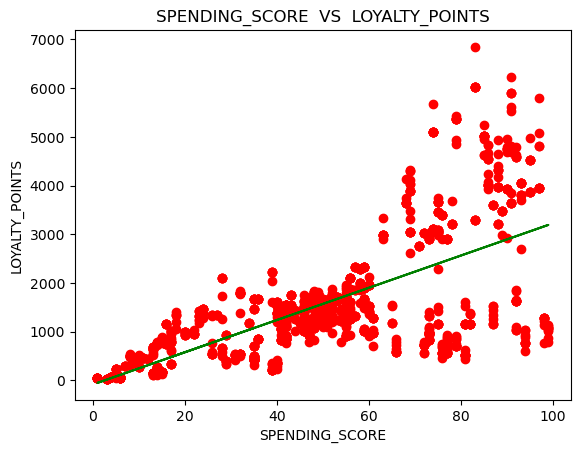

In [16]:
# VISUALISE THE TRAINING SET.

plt.scatter(x_train, y_train, color = 'red')
plt.plot(x_train, y_pred, color = 'green')
plt.title("SPENDING_SCORE  VS  LOYALTY_POINTS")
plt.xlabel("SPENDING_SCORE")
plt.ylabel("LOYALTY_POINTS")
plt.show()

In [17]:
# PRINT THE R-SQUARED, INTERCEPT AND COEFFICIENT VALUE OF THE TRAINING MODEL.

print("R-squared value: ", lt.score(x_train, y_train))
print("Intercept value: ", lt.intercept_)
print("Coefficient value: ", lt.coef_)

R-squared value:  0.4482106227872892
Intercept value:  [-84.002228]
Coefficient value:  [[33.09371761]]


In [18]:
# PREDICT THE TEST SET VALUES.

y_pred_test = lt.predict(x_test)
y_pred_test

array([[  48.37264243],
       [2431.12031027],
       [2265.65172222],
       [1305.93391157],
       [1438.308782  ],
       [1769.24595809],
       [ 246.93494809],
       [2331.83915744],
       [1868.52711092],
       [2927.5260744 ],
       [1570.68365244],
       [1537.58993483],
       [1339.02762918],
       [1206.65275874],
       [ 346.21610091],
       [1703.05852287],
       [1107.37160591],
       [ 280.02866569],
       [ 875.71558265],
       [  81.46636004],
       [1471.40249961],
       [ 478.59097135],
       [ 478.59097135],
       [1372.12134678],
       [1769.24595809],
       [1537.58993483],
       [2894.43235679],
       [ 776.43442983],
       [ 180.74751287],
       [2795.15120396],
       [ 941.90301787],
       [ 313.1223833 ],
       [ 246.93494809],
       [1438.308782  ],
       [1603.77737005],
       [1636.87108765],
       [1405.21506439],
       [1736.15224048],
       [1636.87108765],
       [1405.21506439],
       [ 875.71558265],
       [1868.527

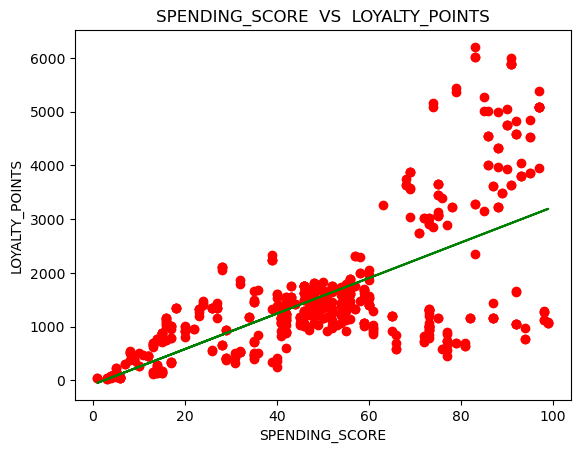

In [19]:
# VISUALISE THE TEST SET.

plt.scatter(x_test, y_test, color = 'red')
plt.plot(x_test, y_pred_test, color = 'green')
plt.title("SPENDING_SCORE  VS  LOYALTY_POINTS")
plt.xlabel("SPENDING_SCORE")
plt.ylabel("LOYALTY_POINTS")
plt.savefig("my_plots.png", dpi = 300 , bbox_inches = "tight")
plt.show()

In [20]:
# PRINT THE R-SQUARED, INTERCEPT AND COEFFICIENT VALUE OF THE TEST MODEL.

print("R-squared value: ", lt.score(x_test, y_test))
print("Intercept value: ", lt.intercept_)
print("Coefficient value: ", lt.coef_)

R-squared value:  0.4608058962879793
Intercept value:  [-84.002228]
Coefficient value:  [[33.09371761]]


### ***REMUNERATION VS LOYALTY***

In [21]:
# DEFINE THE DEPENDENT VARIABLE.
y = tr['loyalty_points'].values.reshape(-1,1)

# DEFINE THE INDEPENDENT VARIABLE.
x = tr['remuneration'].values.reshape(-1,1)

# FIT THE MODEL.
lt = LinearRegression()
lt.fit(x,y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [22]:
# SPLIT THE DATA INTO TRAINING = 0.7 AND TESTING = 0.3 SUBSETS.
x_train, x_test, y_train, y_test = train_test_split(x, y,\
                                                    train_size = 0.7,\
                                                    random_state = 42)

# FIT THE MODEL ONCE AGAIN WITH TRAIN DATA.
lt.fit(x_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [23]:
# PREDICT THE TRAINING SET VALUES.

y_pred = lt.predict(x_train)
y_pred

array([[ 883.16521296],
       [2452.97497895],
       [2162.26946673],
       ...,
       [1232.01182762],
       [1232.01182762],
       [1958.77560818]], shape=(1400, 1))

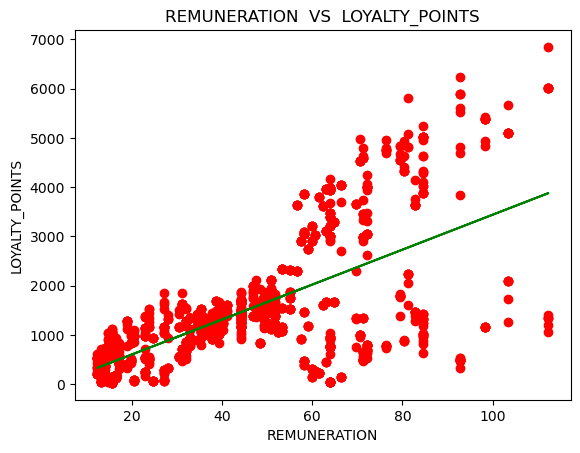

In [24]:
# VISUALISE THE TRAINING SET.

plt.scatter(x_train, y_train, color = 'red')
plt.plot(x_train, y_pred, color = 'green')
plt.title("REMUNERATION  VS  LOYALTY_POINTS")
plt.xlabel("REMUNERATION")
plt.ylabel("LOYALTY_POINTS")
plt.show()

In [25]:
# PRINT THE R-SQUARED, INTERCEPT AND COEFFICIENT VALUE OF THE TRAINING MODEL.

print("R-squared value: ", lt.score(x_train, y_train))
print("Intercept value: ", lt.intercept_)
print("Coefficient value: ", lt.coef_)

R-squared value:  0.40256506842380835
Intercept value:  [-105.23352859]
Coefficient value:  [[35.45189173]]


In [26]:
# PREDICT THE TEST SET VALUES.

y_pred_test = lt.predict(x_test)
y_pred_test

array([[ 766.88300807],
       [2162.26946673],
       [1987.8461594 ],
       [1697.14064718],
       [1580.85844229],
       [1348.29403251],
       [2045.98726184],
       [ 592.45970074],
       [1290.15293007],
       [1900.63450573],
       [1173.87072518],
       [1638.99954473],
       [1842.49340329],
       [2772.75104239],
       [2452.97497895],
       [1464.5762374 ],
       [2133.19891551],
       [1958.77560818],
       [ 563.38914952],
       [ 621.53025196],
       [1464.5762374 ],
       [ 883.16521296],
       [2889.03324728],
       [1464.5762374 ],
       [1232.01182762],
       [1668.07009595],
       [2598.32773506],
       [2365.76332528],
       [3179.7387595 ],
       [ 737.81245685],
       [ 737.81245685],
       [2133.19891551],
       [2423.90442773],
       [1726.2111984 ],
       [1464.5762374 ],
       [1115.72962274],
       [1144.80017396],
       [1609.92899351],
       [1464.5762374 ],
       [1144.80017396],
       [1929.70505695],
       [1290.152

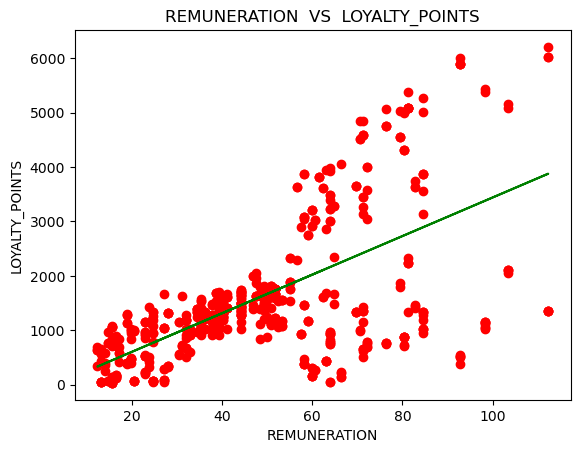

In [27]:
# VISUALISE THE TEST SET.

plt.scatter(x_test, y_test, color = 'red')
plt.plot(x_test, y_pred_test, color = 'green')
plt.title("REMUNERATION  VS  LOYALTY_POINTS")
plt.xlabel("REMUNERATION")
plt.ylabel("LOYALTY_POINTS")
plt.savefig("my_plots1.png", dpi = 300 , bbox_inches = "tight")
plt.show()

In [28]:
# PRINT THE R-SQUARED, INTERCEPT AND COEFFICIENT VALUE OF THE TEST MODEL.

print("R-squared value: ", lt.score(x_test, y_test))
print("Intercept value: ", lt.intercept_)
print("Coefficient value: ", lt.coef_)

R-squared value:  0.3217393070829693
Intercept value:  [-105.23352859]
Coefficient value:  [[35.45189173]]


### ***AGE VS LOYALTY POINTS***

In [29]:
# DEFINE THE DEPENDENT VARIABLE.
y = tr['loyalty_points'].values.reshape(-1,1)

# DEFINE THE INDEPENDENT VARIABLE.
x = tr['age'].values.reshape(-1,1)

# FIT THE MODEL.
lt = LinearRegression()
lt.fit(x,y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [30]:
# SPLIT THE DATA INTO TRAINING = 0.7 AND TESTING = 0.3 SUBSETS.
x_train, x_test, y_train, y_test = train_test_split(x, y,\
                                                    train_size = 0.7,\
                                                    random_state = 42)

# FIT THE MODEL ONCE AGAIN WITH TRAIN DATA.
lt.fit(x_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [31]:
# PREDICT THE TRAINING SET VALUES.

y_pred = lt.predict(x_train)
y_pred

array([[1583.43869758],
       [1612.83999421],
       [1612.83999421],
       ...,
       [1465.83351109],
       [1539.33675265],
       [1579.76353551]], shape=(1400, 1))

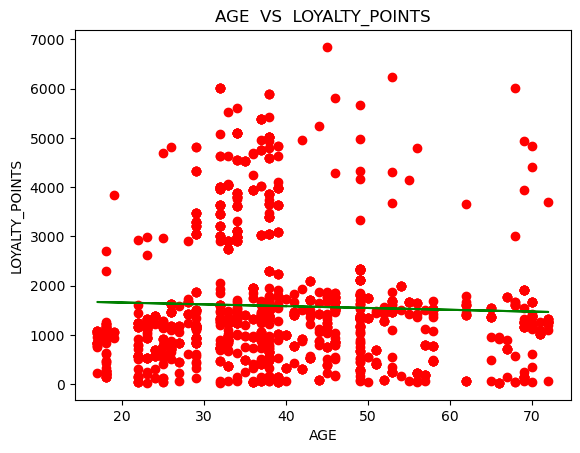

In [32]:
# VISUALISE THE TRAINING SET.

plt.scatter(x_train, y_train, color = 'red')
plt.plot(x_train, y_pred, color = 'green')
plt.title("AGE  VS  LOYALTY_POINTS")
plt.xlabel("AGE")
plt.ylabel("LOYALTY_POINTS")
plt.show()

In [33]:
# PRINT THE R-SQUARED, INTERCEPT AND COEFFICIENT VALUE OF THE TRAINING MODEL.

print("R-squared value: ", lt.score(x_train, y_train))
print("Intercept value: ", lt.intercept_)
print("Coefficient value: ", lt.coef_)

R-squared value:  0.0015194042494702797
Intercept value:  [1730.4451807]
Coefficient value:  [[-3.67516208]]


In [34]:
# PREDICT THE TEST SET VALUES.

y_pred_test = lt.predict(x_test)
y_pred_test

array([[1465.83351109],
       [1590.78902174],
       [1609.16483213],
       [1645.91645291],
       [1550.36223888],
       [1502.58513187],
       [1664.2922633 ],
       [1587.11385966],
       [1660.61710122],
       [1587.11385966],
       [1546.68707681],
       [1561.38772512],
       [1546.68707681],
       [1587.11385966],
       [1543.01191473],
       [1627.54064252],
       [1561.38772512],
       [1517.28578018],
       [1550.36223888],
       [1609.16483213],
       [1517.28578018],
       [1491.55964564],
       [1605.48967005],
       [1568.73804927],
       [1590.78902174],
       [1649.59161499],
       [1594.46418382],
       [1550.36223888],
       [1601.81450797],
       [1638.56612875],
       [1590.78902174],
       [1631.2158046 ],
       [1590.78902174],
       [1535.66159057],
       [1524.63610434],
       [1550.36223888],
       [1612.83999421],
       [1473.18383525],
       [1638.56612875],
       [1550.36223888],
       [1638.56612875],
       [1590.789

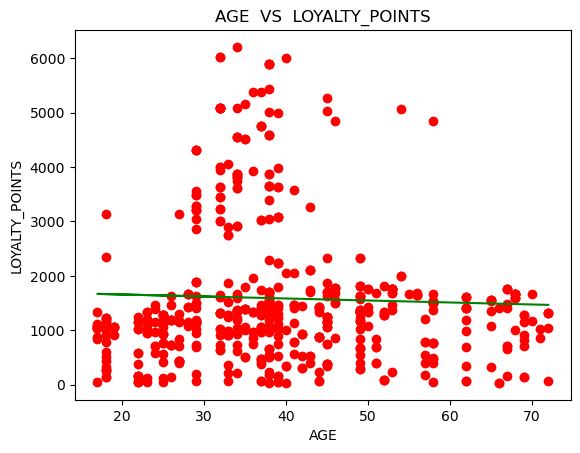

In [35]:
# VISUALISE THE TEST SET.

plt.scatter(x_test, y_test, color = 'red')
plt.plot(x_test, y_pred_test, color = 'green')
plt.title("AGE  VS  LOYALTY_POINTS")
plt.xlabel("AGE")
plt.ylabel("LOYALTY_POINTS")
plt.savefig("my_plots2.png", dpi = 300 , bbox_inches = "tight")
plt.show()

In [36]:
# PRINT THE R-SQUARED, INTERCEPT AND COEFFICIENT VALUE OF THE TEST MODEL.

print("R-squared value: ", lt.score(x_test, y_test))
print("Intercept value: ", lt.intercept_)
print("Coefficient value: ", lt.coef_)

R-squared value:  0.002088348289358777
Intercept value:  [1730.4451807]
Coefficient value:  [[-3.67516208]]


# ***EXPLORING THE STRUCTURE USING DECISION TREES***

### ***LOAD AND PREPARE THE DATA***

In [37]:
# IMPORT ALL THE NECESSARY LIBRARIES.

import numpy as np
import pandas as pd
import scipy as scp
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
import statsmodels.api as sm
import math
import warnings
import matplotlib.pyplot as plt

In [38]:
tr.head()

,gender,age,remuneration,spending_score,loyalty_points,education,product,review,summary
0,Male,18,12.30,39,210,graduate,453,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,Male,23,12.30,81,524,graduate,466,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,Female,22,13.12,6,40,graduate,254,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Female,25,13.12,77,562,graduate,263,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,Female,33,13.94,40,366,graduate,291,As my review of GF9's previous screens these w...,Money trap


In [39]:
# CREATE A NEW DATAFRAME CONTAINING THE REQUIRED COLUMNS.

tr2 = tr.drop(columns=['gender' , 'education' , 'product' , 'review' , 'summary'])
tr2.head()

,age,remuneration,spending_score,loyalty_points
0,18,12.30,39,210
1,23,12.30,81,524
2,22,13.12,6,40
3,25,13.12,77,562
4,33,13.94,40,366


### ***DECISION TREE REGRESSOR***

In [40]:
# SPECIFY X AS THE INDEPENDENT VARIABLE AND y AS THE DEPENDENT VARIABLE.
tr2_cols = tr2.columns[tr2.columns != 'loyalty_points']

X = tr2[tr2_cols]
y = tr2['loyalty_points']

In [41]:
# SPLIT THE DATA INTO TRAINING = 0.7 AND TESTING = 0.3 SUBSETS.
X_train, X_test, y_train, y_test = train_test_split(X, y,\
                                                    train_size = 0.7,\
                                                    random_state = 42)

In [42]:
#BUILD AND FIT THE MODEL.

tr2_regressor = DecisionTreeRegressor(random_state=42)

tr2_regressor.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [43]:
# PREDICT THE RESPONSE FOR THE DATA TEST.

y_pred1 = tr2_regressor.predict(X_test)

y_pred1

array([  65., 3398., 2750., 1122., 1622., 1605.,  266.,  994., 1060.,
       3634., 1338., 1777., 1752., 2235.,  696., 1430., 1675.,  463.,
        406.,   67., 1504.,  338.,  969., 1424., 1623., 1248., 4747.,
       1344.,  500., 1151.,  515.,  443.,  499., 1751., 1651., 1328.,
       1177., 1658., 1281., 1177.,  926., 1623., 1395., 5084., 5434.,
        238., 1751., 1622., 1322., 1264.,  871.,  942.,  904.,  179.,
       1601.,  996.,  664., 5249.,  881., 3285., 1404., 1281., 1098.,
       1622., 1346.,  649., 3636.,  145., 1222., 1391., 1328., 4320.,
       5377., 1177., 3478.,  926., 1492., 3636., 1347.,  334., 1232.,
       1014., 1379.,  871., 1071., 1605.,  478., 1281., 1703., 1129.,
       4944., 1278.,  138., 1503.,  133.,   60., 1395., 1042.,  952.,
       1232., 1547., 5895., 1151.,  648., 1159., 1379.,  476., 1338.,
       1067.,  443., 3455., 1684., 1637.,  994., 3015.,  881., 1673.,
       4588.,  925., 1233.,  236.,  338., 1751., 1376., 5895., 4968.,
       1355., 1998.,

In [44]:
# DETERMINE THE ACCURACY OF THE MODEL.

print("Mean Absolute Error: " , metrics.mean_absolute_error(y_test, y_pred1))
print("Mean Squared Error: " , metrics.mean_squared_error(y_test, y_pred1))
print("Root Mean Squared Error: " , math.sqrt(metrics.mean_squared_error(y_test, y_pred1)))

Mean Absolute Error:  26.175
Mean Squared Error:  6390.525
Root Mean Squared Error:  79.94075931588341


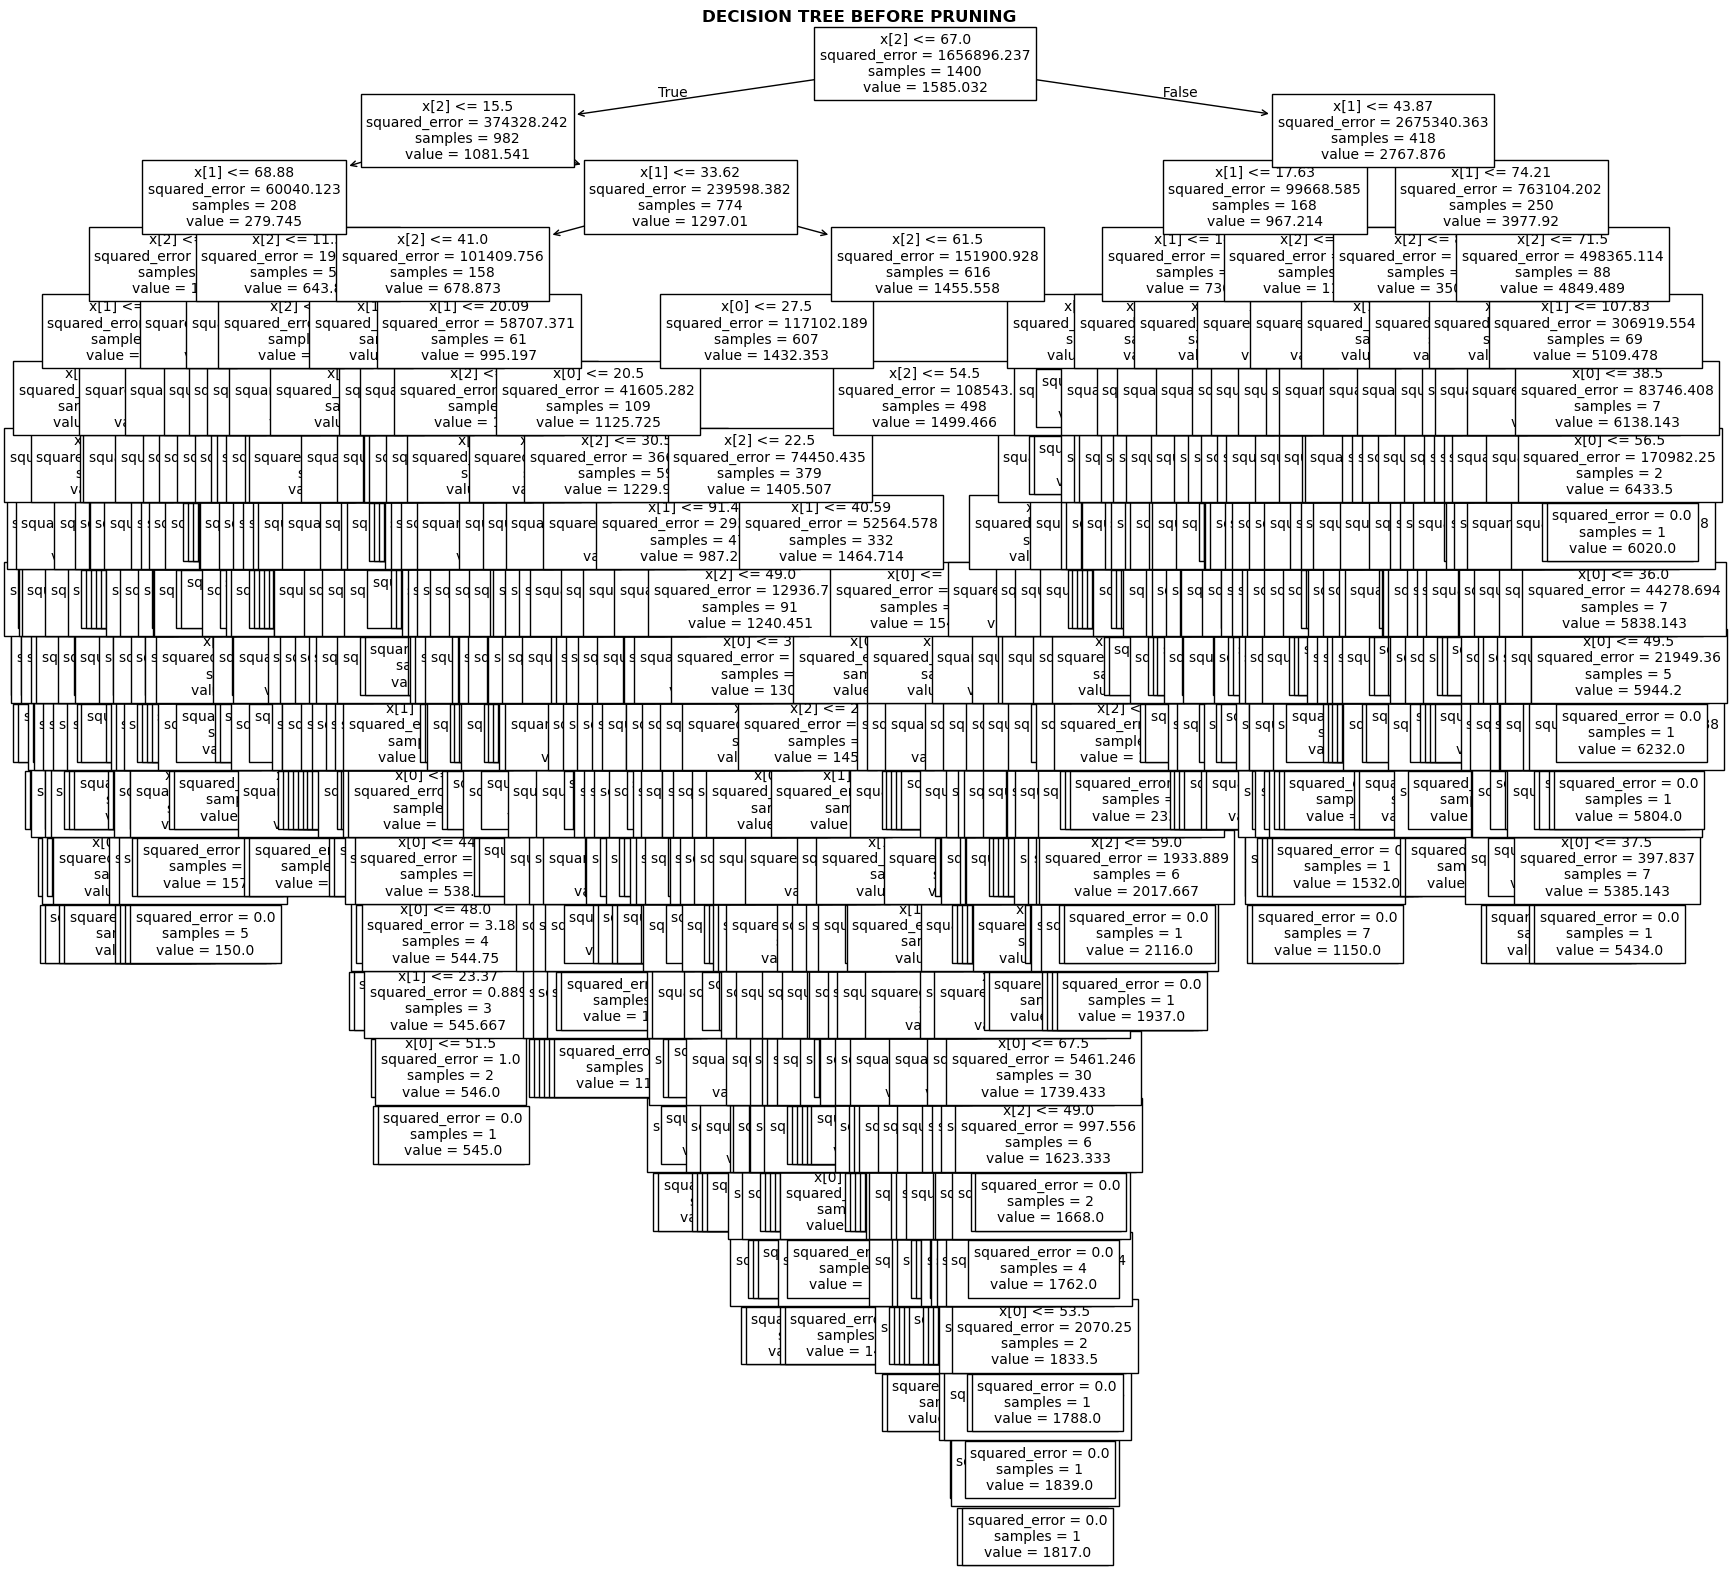

In [45]:
# PLOT THE TREE.

plt.figure(figsize=(20,20))
plot_tree(tr2_regressor, fontsize=10)
plt.title("DECISION TREE BEFORE PRUNING", fontweight = 'bold')
plt.savefig("my_plots3.png", dpi = 600 , bbox_inches = "tight")
plt.show()

### ***POST PRUNING USING COST COMPLEXITY***

In [46]:
# GET THE PRUNING PATH AND ALPHAS.

path = tr2_regressor.cost_complexity_pruning_path(X_train, y_train) 
ccp_alphas = path.ccp_alphas
impurities = path.impurities

In [47]:
# TEST MULTIPLE ALPHAS TO FIND THE BEST MODEL.

models = []

for ccp_alpha in ccp_alphas:
    model = DecisionTreeRegressor(random_state=42, ccp_alpha=ccp_alpha)
    model.fit(X_train, y_train)
    models.append(model)

In [48]:
# EVALUATE AND SELECT THE BEST ALPHA.

train_scores = [metrics.mean_squared_error(y_train, m.predict(X_train)) for m in models]
test_scores = [metrics.mean_squared_error(y_test, m.predict(X_test)) for m in models]

In [49]:
best_alpha = ccp_alphas[test_scores.index(min(test_scores))]
print(f"Optimal alpha: {best_alpha}")

Optimal alpha: 0.0032142857142857142


In [50]:
# BUILD THE FINAL PRUNED TREE.

best_post_pruned_tree = DecisionTreeRegressor(random_state=42, ccp_alpha=best_alpha)
best_post_pruned_tree.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,np.float64(0....2857142857142)


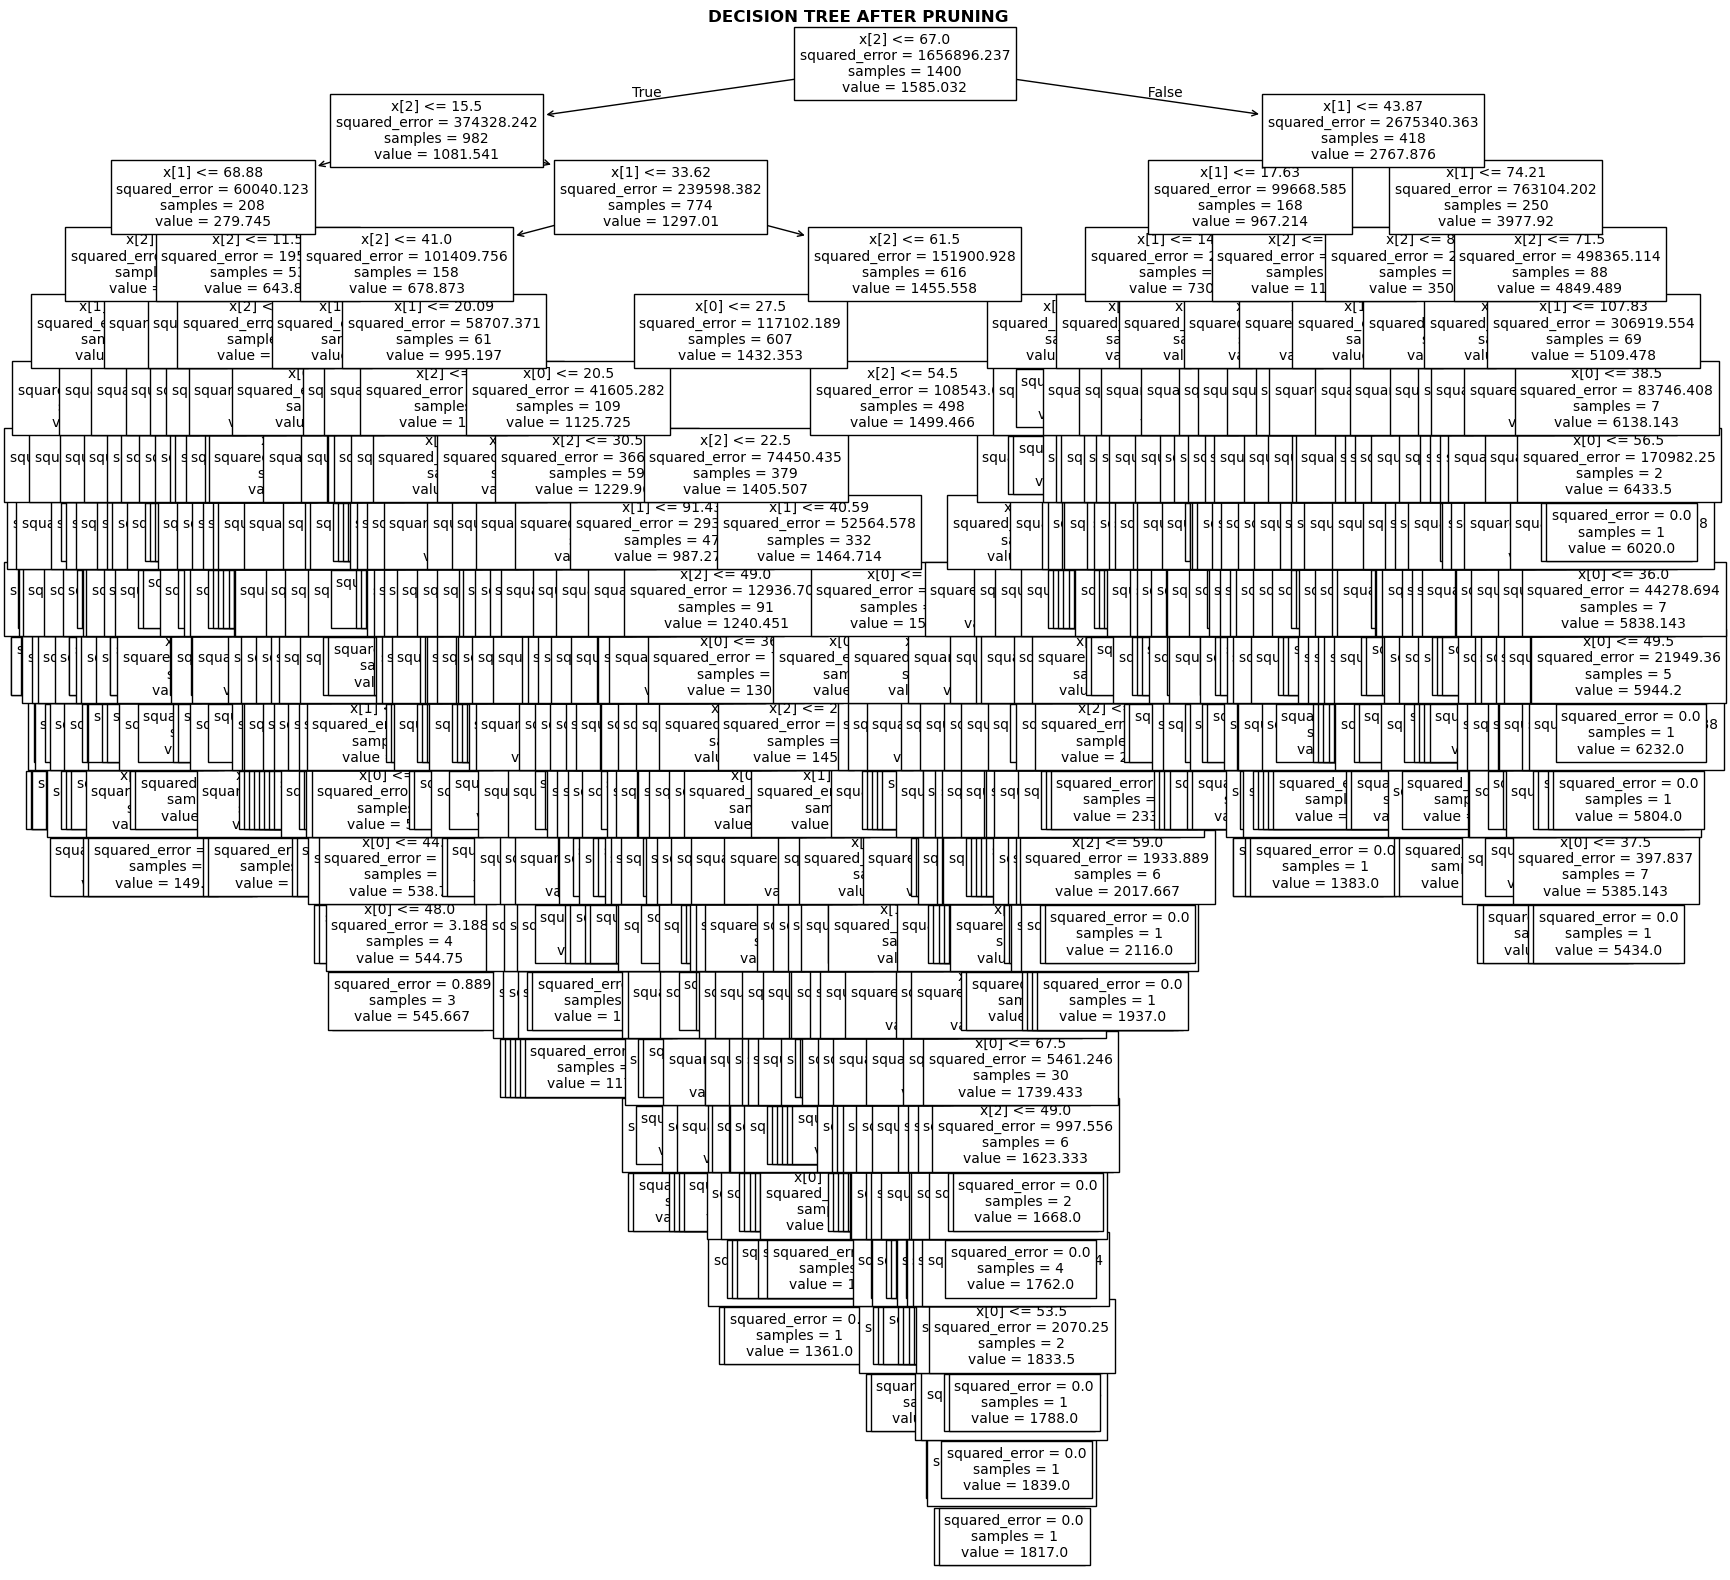

In [51]:
# PLOT THE FINAL PRUNED TREE.

plt.figure(figsize=(20,20))
plot_tree(best_post_pruned_tree, fontsize=10)
plt.title("DECISION TREE AFTER PRUNING", fontweight = 'bold')
plt.savefig("my_plots4.png", dpi = 600 , bbox_inches = "tight")
plt.show()

In [52]:
# PREDICT THE RESPONSE FOR THE DATA TEST OF THE PRUNED MODEL.

y_pred2 = best_post_pruned_tree.predict(X_test)

In [53]:
# DETERMINE THE THE ACCURACY OF THE PRUNED MODEL.

print("Mean Absolute Error: " , metrics.mean_absolute_error(y_test, y_pred2))
print("Mean Squared Error: " , metrics.mean_squared_error(y_test, y_pred2))
print("Root Mean Squared Error: " , math.sqrt(metrics.mean_squared_error(y_test, y_pred2)))

Mean Absolute Error:  26.197619047619046
Mean Squared Error:  6389.700728854876
Root Mean Squared Error:  79.93560363727089


## ***CLUSTERING WITH K-MEANS USING PYTHON***

### ***PREPARE THE DATA***

In [54]:
# DROP UNNECESSARY COLUMNS

tr3 = tr.drop(columns=['gender' , 'education' , 'product' , 'review' , 'summary' , 'age'])
tr3.head()

,remuneration,spending_score,loyalty_points
0,12.30,39,210
1,12.30,81,524
2,13.12,6,40
3,13.12,77,562
4,13.94,40,366


In [55]:
tr3.describe()

,remuneration,spending_score,loyalty_points
count,2000.000000,2000.000000,2000.000000
mean,48.079060,50.000000,1578.032000
std,23.123984,26.094702,1283.239705
min,12.300000,1.000000,25.000000
25%,30.340000,32.000000,772.000000
50%,47.150000,50.000000,1276.000000
75%,63.960000,73.000000,1751.250000
max,112.340000,99.000000,6847.000000


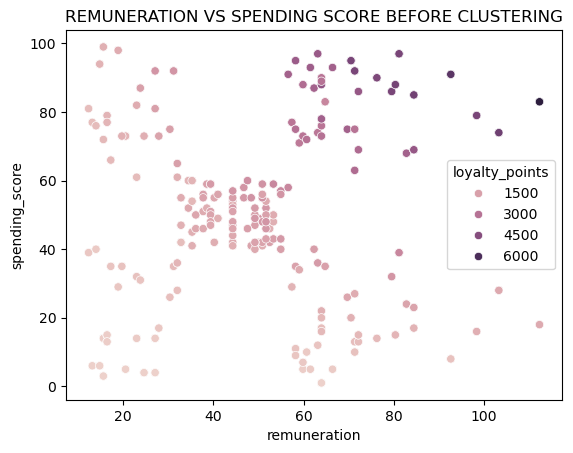

In [62]:
# CREATE A SCATTERPLOT WITH SEABORN.

sns.scatterplot(x='remuneration',\
                y='spending_score',\
                data=tr3,
                hue='loyalty_points').set_title("REMUNERATION VS SPENDING SCORE BEFORE CLUSTERING")\
    .get_figure().savefig("my_plots5.png", dpi = 300 , bbox_inches = "tight")

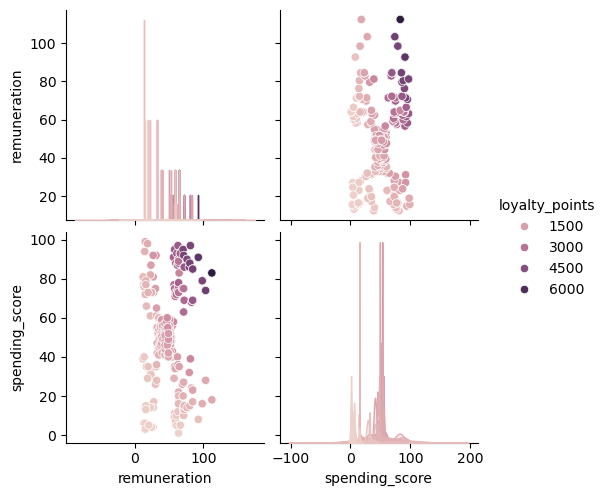

In [60]:
# CREATE A PAIRPLOT WITH SEABORN.

x = tr3[['remuneration' , 'spending_score']]

sns.pairplot(tr3,\
             vars = x,\
             hue = 'loyalty_points',\
             diag_kind = 'kde').savefig("my_plots6.png", dpi = 300 , bbox_inches = "tight")

#### ***ELBOW METHOD***

In [64]:
# IMPORT THE K-MEANS CLASS.
from sklearn.cluster import KMeans

# ELBOW CHART FOR US TO DECIDE ON THE NUMBBER F OPTIMAL CLUSTERS.

ss = []
for i in range(1,11):
    kmeans = KMeans(n_clusters = i,\
                    init = 'k-means++',\
                    max_iter = 500,\
                    n_init = 10,\
                    random_state = 42)
    kmeans.fit(x)
    ss.append(kmeans.inertia_)

C:\Users\Babisha\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(
C:\Users\Babisha\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(
C:\Users\Babisha\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(
C:\Users\Babisha\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak o

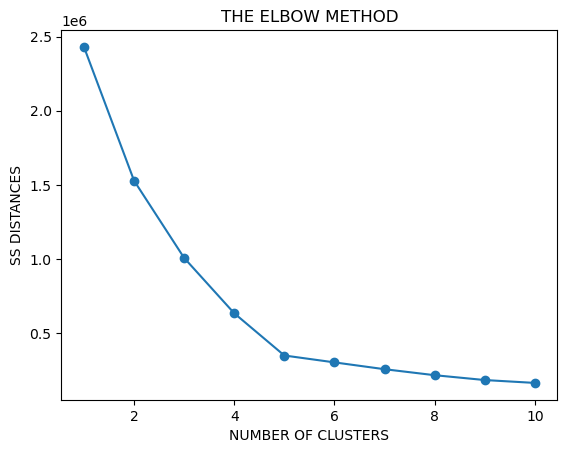

In [65]:
# PLOT THE ELBOW METHOD.

plt.plot(range(1,11),\
         ss,\
         marker ='o')

plt.title("THE ELBOW METHOD")
plt.xlabel("NUMBER OF CLUSTERS")
plt.ylabel("SS DISTANCES")
plt.savefig("my_plots7.png", dpi = 300 , bbox_inches = "tight")
plt.show()

#### ***SILHOUETTE METHOD***

In [66]:
# IMPORT SILHOUETTE_SCORE CLASS FROM SKLEARN.
from sklearn.metrics import silhouette_score

# FIND THE RANGE OF CLUSTERS TO BE USED USING SILHOUETTE METHOD.
sil=[]
kmax = 10
for k in range(2, kmax+1):
    kmeans_s = KMeans(n_clusters = k).fit(x)
    labels = kmeans_s.labels_
    sil.append(silhouette_score(x,\
                               labels,\
                               metric='euclidean') )  

C:\Users\Babisha\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(
C:\Users\Babisha\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(
C:\Users\Babisha\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(
C:\Users\Babisha\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak o

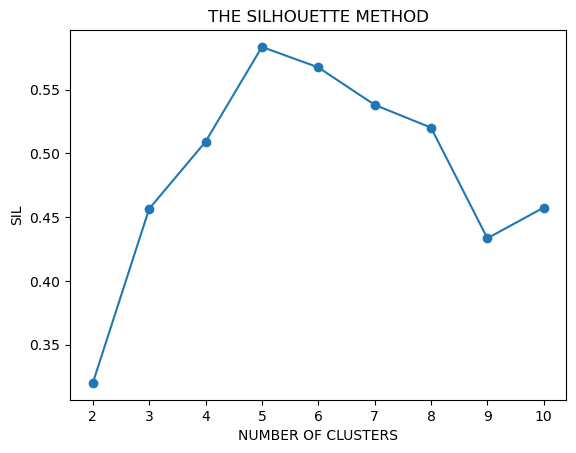

In [67]:
# PLOT THE SILHOUETTE METHOD.

plt.plot(range(2, kmax+1),\
         sil,\
         marker ='o')
plt.title("THE SILHOUETTE METHOD")
plt.xlabel("NUMBER OF CLUSTERS")
plt.ylabel("SIL")
plt.savefig("my_plots8.png", dpi = 300 , bbox_inches = "tight")
plt.show()

#### ***USING 5 CLUSTERS***

In [68]:
# USE 5 CLUSTERS.

kmeans = KMeans(n_clusters = 5,\
                max_iter = 15000,\
                init = 'k-means++',\
                random_state = 42).fit(x)
clusters = kmeans.labels_
x['K-Means Predicted'] = clusters

C:\Users\Babisha\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(


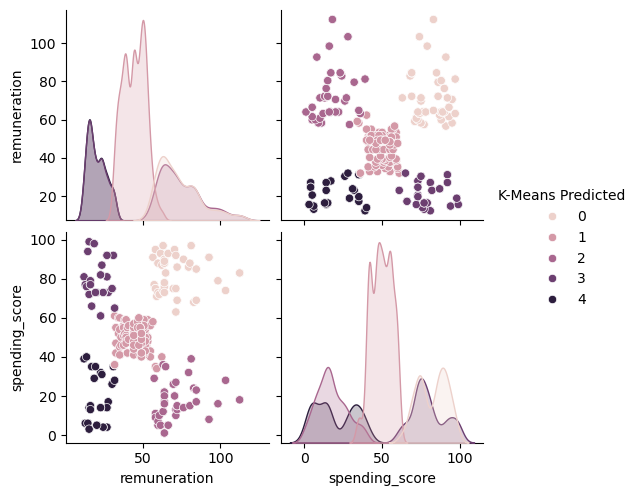

In [69]:
# PLOT THE PREDICTED.

sns.pairplot(x,\
             hue = 'K-Means Predicted',\
             diag_kind = 'kde').savefig("my_plots9.png", dpi = 300 , bbox_inches = "tight")

In [70]:
# CHECK THE NUMBER OF OBSERVATIONS PER PREDICTED CLASS.

x['K-Means Predicted'].value_counts()

K-Means Predicted
1    774
0    356
2    330
4    271
3    269
Name: count, dtype: int64

In [71]:
# VIEW THE K-Means PREDICTED.

x.head()

,remuneration,spending_score,K-Means Predicted
0,12.30,39,4
1,12.30,81,3
2,13.12,6,4
3,13.12,77,3
4,13.94,40,4


#### ***VISUALISING THE CLUSTERS FOR K=5***

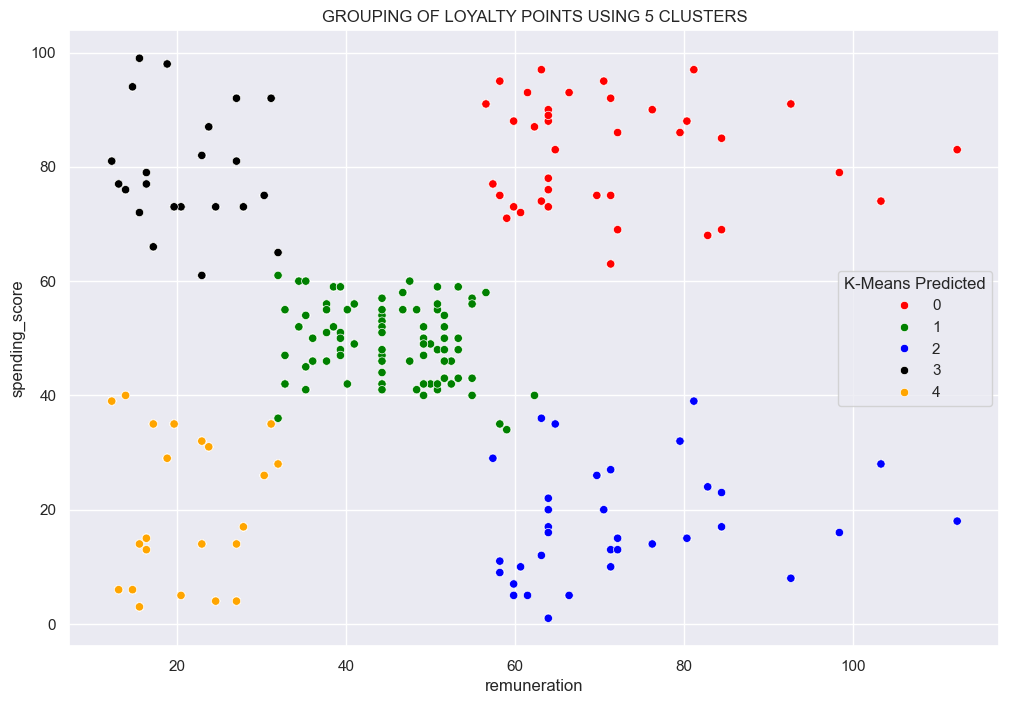

In [72]:
sns.set(rc = {'figure.figsize':(12,8)})

sns.scatterplot(x = 'remuneration',\
                y = 'spending_score',\
                data = x,\
                hue = 'K-Means Predicted',\
                palette = ['red' , 'green' , 'blue' , 'black' , 'orange']).set_title("GROUPING OF LOYALTY POINTS USING 5 CLUSTERS")\
                .get_figure().savefig("my_plots10.png", dpi = 300 , bbox_inches = "tight")

#### ***USING 4 CLUSTERS***

In [73]:
# USE 4 CLUSTERS.

kmeans = KMeans(n_clusters = 4,\
                max_iter = 15000,\
                init = 'k-means++',\
                random_state = 42).fit(x)
clusters = kmeans.labels_
x['K-Means Predicted'] = clusters

C:\Users\Babisha\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(


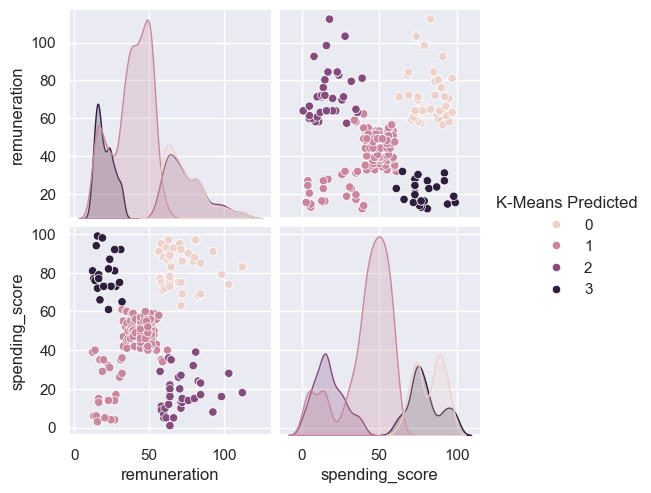

In [74]:
# PLOT THE PREDICTED.

sns.pairplot(x,\
             hue = 'K-Means Predicted',\
             diag_kind = 'kde').savefig("my_plots11.png", dpi = 300 , bbox_inches = "tight")

In [75]:
# CHECK THE NUMBER OF OBSERVATIONS PER PREDICTED CLASS.

x['K-Means Predicted'].value_counts()

K-Means Predicted
1    1045
0     356
2     330
3     269
Name: count, dtype: int64

In [76]:
# VIEW THE K-Means PREDICTED.

x.head()

,remuneration,spending_score,K-Means Predicted
0,12.30,39,1
1,12.30,81,3
2,13.12,6,1
3,13.12,77,3
4,13.94,40,1


#### ***VISUALISING THE CLUSTERS FOR K=5***

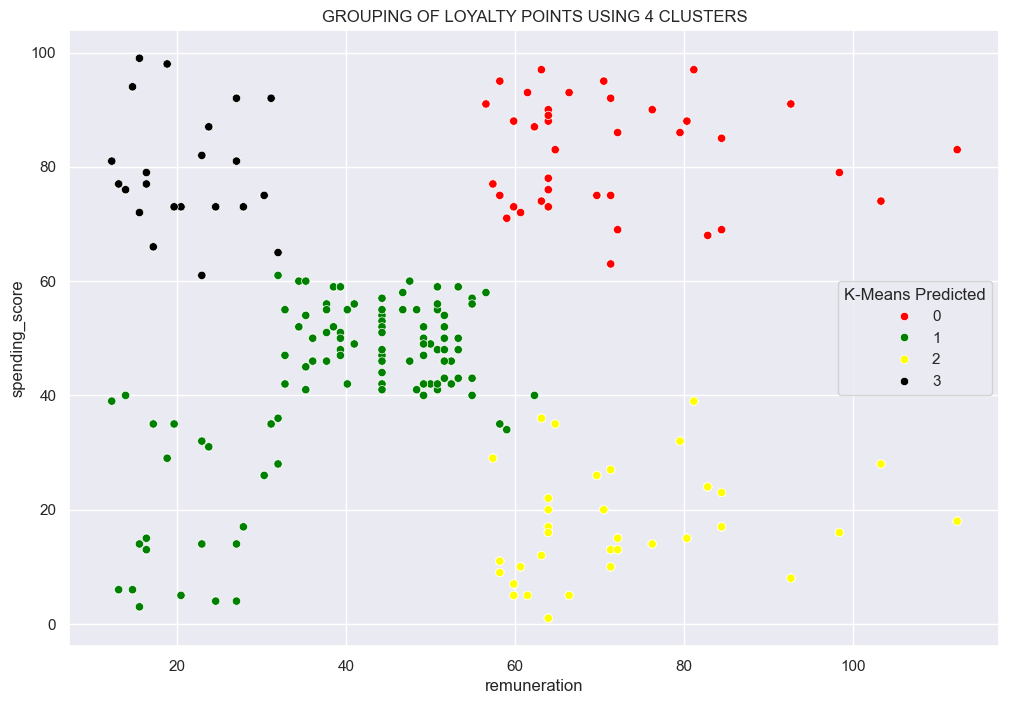

In [77]:
sns.set(rc = {'figure.figsize':(12,8)})

sns.scatterplot(x = 'remuneration',\
                y = 'spending_score',\
                data = x,\
                hue = 'K-Means Predicted',\
                palette = ['red' , 'green' , 'yellow' , 'black']).set_title("GROUPING OF LOYALTY POINTS USING 4 CLUSTERS").\
                get_figure().savefig("my_plots12.png", dpi = 300 , bbox_inches = "tight")
              

## ***NLP USING PYTHON***

### ***LOAD AND EXPLORE THE DATA***

In [78]:
# IMPORT THE NECESSARY LIBRARIES

import nltk
import os
from wordcloud import WordCloud
from nltk.tokenize import word_tokenize
from nltk.probability import FreqDist
from nltk.corpus import stopwords
from textblob import TextBlob
from scipy.stats import norm
from collections import Counter

In [79]:
# DROP THE UNNECESSARY COLUMNS.

tr4 = tr.drop(columns=['gender' , 'education' , 'product', 'age' , 'remuneration' , 'spending_score' , 'loyalty_points'])

In [80]:
tr4.head()

,review,summary
0,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,As my review of GF9's previous screens these w...,Money trap


### ***PREPARE THE DATA FOR NLP***

In [81]:
# Review: Change all to lowercase.

tr4['review'] = tr4['review'].apply(lambda x: " ".join(x.lower() for x in x.split()))
tr4['review'].head()

0    when it comes to a dm's screen, the space on t...
1    an open letter to galeforce9*: your unpainted ...
2    nice art, nice printing. why two panels are fi...
3    amazing buy! bought it as a gift for our new d...
4    as my review of gf9's previous screens these w...
Name: review, dtype: object

In [82]:
# Summary: Change all to lowercase.

tr4['summary'] = tr4['summary'].apply(lambda x: " ".join(x.lower() for x in x.split()))
tr4['summary'].head()

0    the fact that 50% of this space is wasted on a...
1    another worthless dungeon master's screen from...
2                      pretty, but also pretty useless
3                                           five stars
4                                           money trap
Name: summary, dtype: object

In [83]:
# Review: Remove Punctuation.

tr4["review"] = tr4["review"].str.replace(r"[^\w\s]" , "", regex = True)

In [84]:
tr4.shape

(2000, 2)

In [85]:
tr4['review'].head()

0    when it comes to a dms screen the space on the...
1    an open letter to galeforce9 your unpainted mi...
2    nice art nice printing why two panels are fill...
3    amazing buy bought it as a gift for our new dm...
4    as my review of gf9s previous screens these we...
Name: review, dtype: object

In [86]:
# Summary: Remove Punctuation.

tr4["summary"] = tr4["summary"].str.replace(r"[^\w\s]" , "", regex = True)

In [87]:
tr4['summary'].head()

0    the fact that 50 of this space is wasted on ar...
1    another worthless dungeon masters screen from ...
2                       pretty but also pretty useless
3                                           five stars
4                                           money trap
Name: summary, dtype: object

In [88]:
# DROP DUPLICATES IN BOTH COLUMNS.

# DETERMINE THE NO OF DUPLICATES IN REVIEW.
tr4.review.duplicated().sum()

np.int64(50)

In [89]:
# DETERMINE THE NO OF DUPLICATES IN SUMMARY

tr4.summary.duplicated().sum()

np.int64(649)

In [90]:
# REMOVE DUPLICATES IN REVIEW.

tr_dup_cleanr = tr4.drop_duplicates(subset=['review'])
tr_dup_cleanr.reset_index(inplace = True)

In [91]:
tr_dup_cleanr.shape

(1950, 3)

In [92]:
# REMOVE DUPLICATES IN SUMMARY.

tr_dup_cleans = tr_dup_cleanr.drop_duplicates(subset=['summary'])
tr_dup_cleans.reset_index(inplace=True)

In [93]:
tr_dup_cleans.shape

(1349, 4)

In [94]:
# Create a wordcloud before removing stopwords.
all_review = ''
for i in range(tr_dup_cleans.shape[0]):
    all_review = all_review + tr_dup_cleans['review'][i]

In [95]:
# SET THE COLOUR PALETTE

word_cloudr = WordCloud(width = 1600 , height = 900,\
                        background_color = 'white',\
                        colormap = 'plasma',\
                        stopwords = 'none',\
                         min_font_size = 10).generate(all_review)


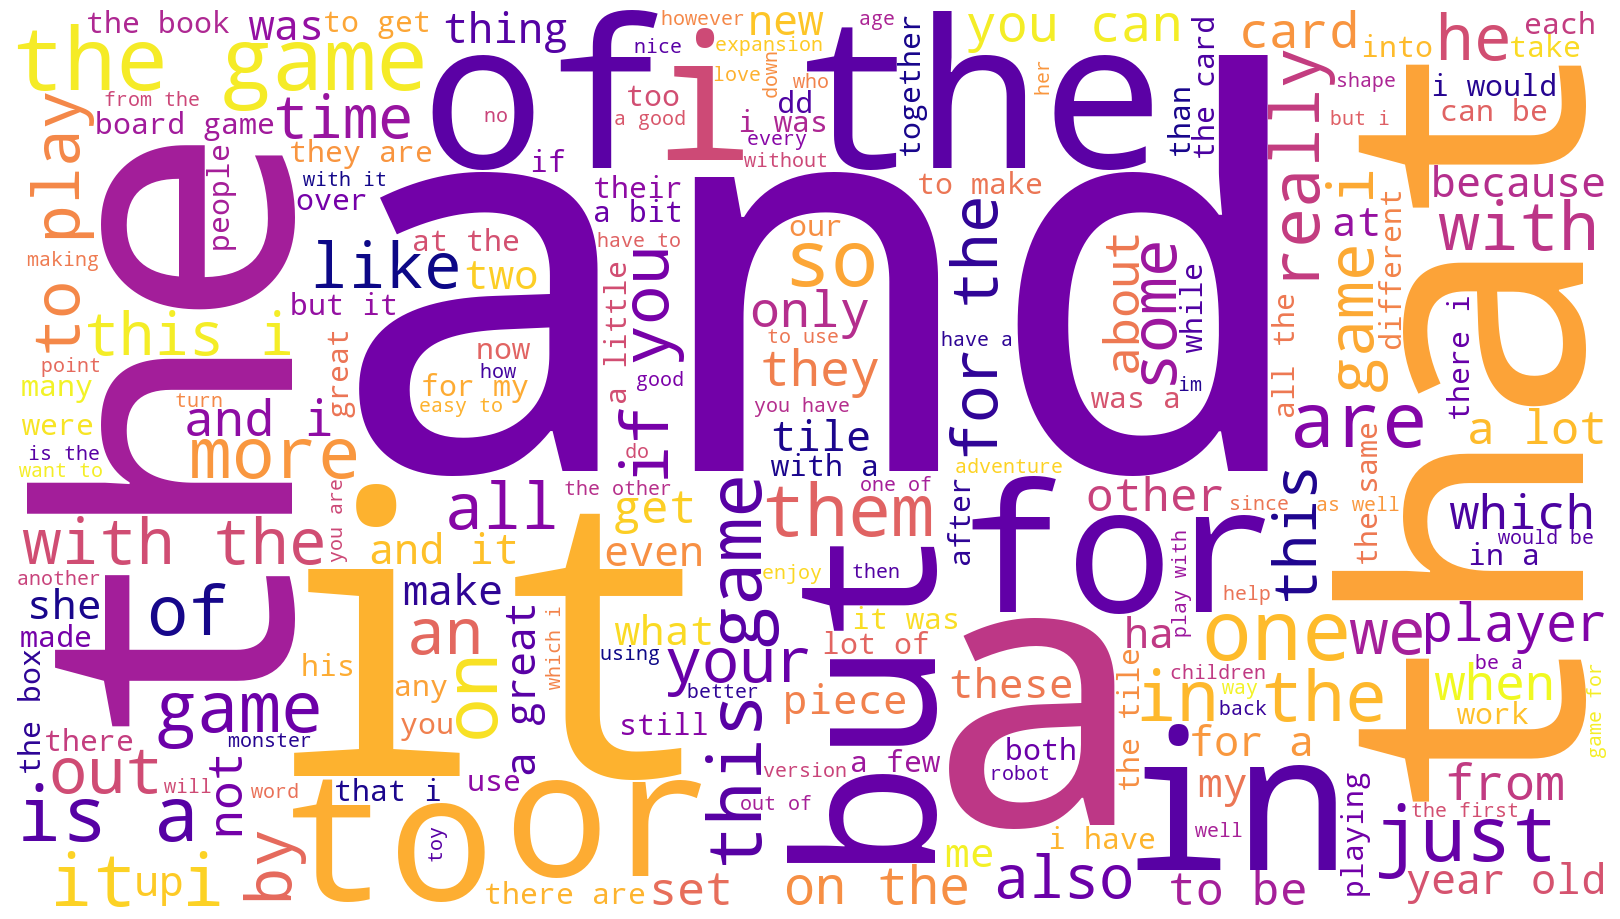

In [96]:
#  REVIEW: PLOT THE WORDCLOUD

plt.figure(figsize = (16,9), facecolor = None)
plt.imshow(word_cloudr)
plt.axis('off')
plt.tight_layout(pad = 0)
plt.show()

In [97]:
# Apply tokenization to both columns.

nltk.download('punkt')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Babisha\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [98]:
# APPLYING TOKENISATION TO REVIEW.

tr_dup_cleans['review_tokens'] = tr_dup_cleans['review'].apply(word_tokenize)

C:\Users\Babisha\AppData\Local\Temp\ipykernel_23712\1521399794.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  tr_dup_cleans['review_tokens'] = tr_dup_cleans['review'].apply(word_tokenize)


In [99]:
tr_dup_cleans['review_tokens'].head()

0    [when, it, comes, to, a, dms, screen, the, spa...
1    [an, open, letter, to, galeforce9, your, unpai...
2    [nice, art, nice, printing, why, two, panels, ...
3    [amazing, buy, bought, it, as, a, gift, for, o...
4    [as, my, review, of, gf9s, previous, screens, ...
Name: review_tokens, dtype: object

In [100]:
# APPLYING TOKENS TO SUMMARY.

tr_dup_cleans['summary_tokens'] = tr_dup_cleans['summary'].apply(word_tokenize)

C:\Users\Babisha\AppData\Local\Temp\ipykernel_23712\4181009299.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  tr_dup_cleans['summary_tokens'] = tr_dup_cleans['summary'].apply(word_tokenize)


In [101]:
tr_dup_cleans['summary_tokens'].head()

0    [the, fact, that, 50, of, this, space, is, was...
1    [another, worthless, dungeon, masters, screen,...
2                 [pretty, but, also, pretty, useless]
3                                        [five, stars]
4                                        [money, trap]
Name: summary_tokens, dtype: object

In [102]:
# DEFINE AN EMPTY LIST OF TOKENS FOR REVIEW.

all_review_tokens = []
for i in range(tr_dup_cleans.shape[0]):
    all_review_tokens = all_review_tokens + tr_dup_cleans['review_tokens'][i]

In [103]:
# Calculate the Frequency Distribution.

fdist = FreqDist(all_review_tokens)
fdist

FreqDist({'the': 5019, 'and': 2934, 'to': 2843, 'a': 2829, 'of': 2261, 'i': 1887, 'it': 1830, 'is': 1593, 'this': 1549, 'for': 1360, ...})

In [104]:
# REMOVE ALPHANUMERIC.

tokens_r = [word for word in all_review_tokens if word.isalnum()]

In [105]:
# REMOVE STOPWORDS.

nltk.download('stopwords')
from nltk.corpus import stopwords
english_stopwords = set(stopwords.words('english'))
tokens_r2 = [x for x in tokens_r if x.lower() not in english_stopwords]
tokens_r2_string = ''
for value in tokens_r2:
    tokens_r2_string = tokens_r2_string + value + ' '

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Babisha\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [106]:
# PLOT THE WORDCLOUD IMAGE OF REVIEW AFTER REMOVING STOPWORDS.

word_cloudrt = WordCloud(width = 1600 , height = 900,\
                        background_color = 'white',\
                        colormap = 'plasma',\
                        stopwords = 'none',\
                         min_font_size = 10).generate(tokens_r2_string)

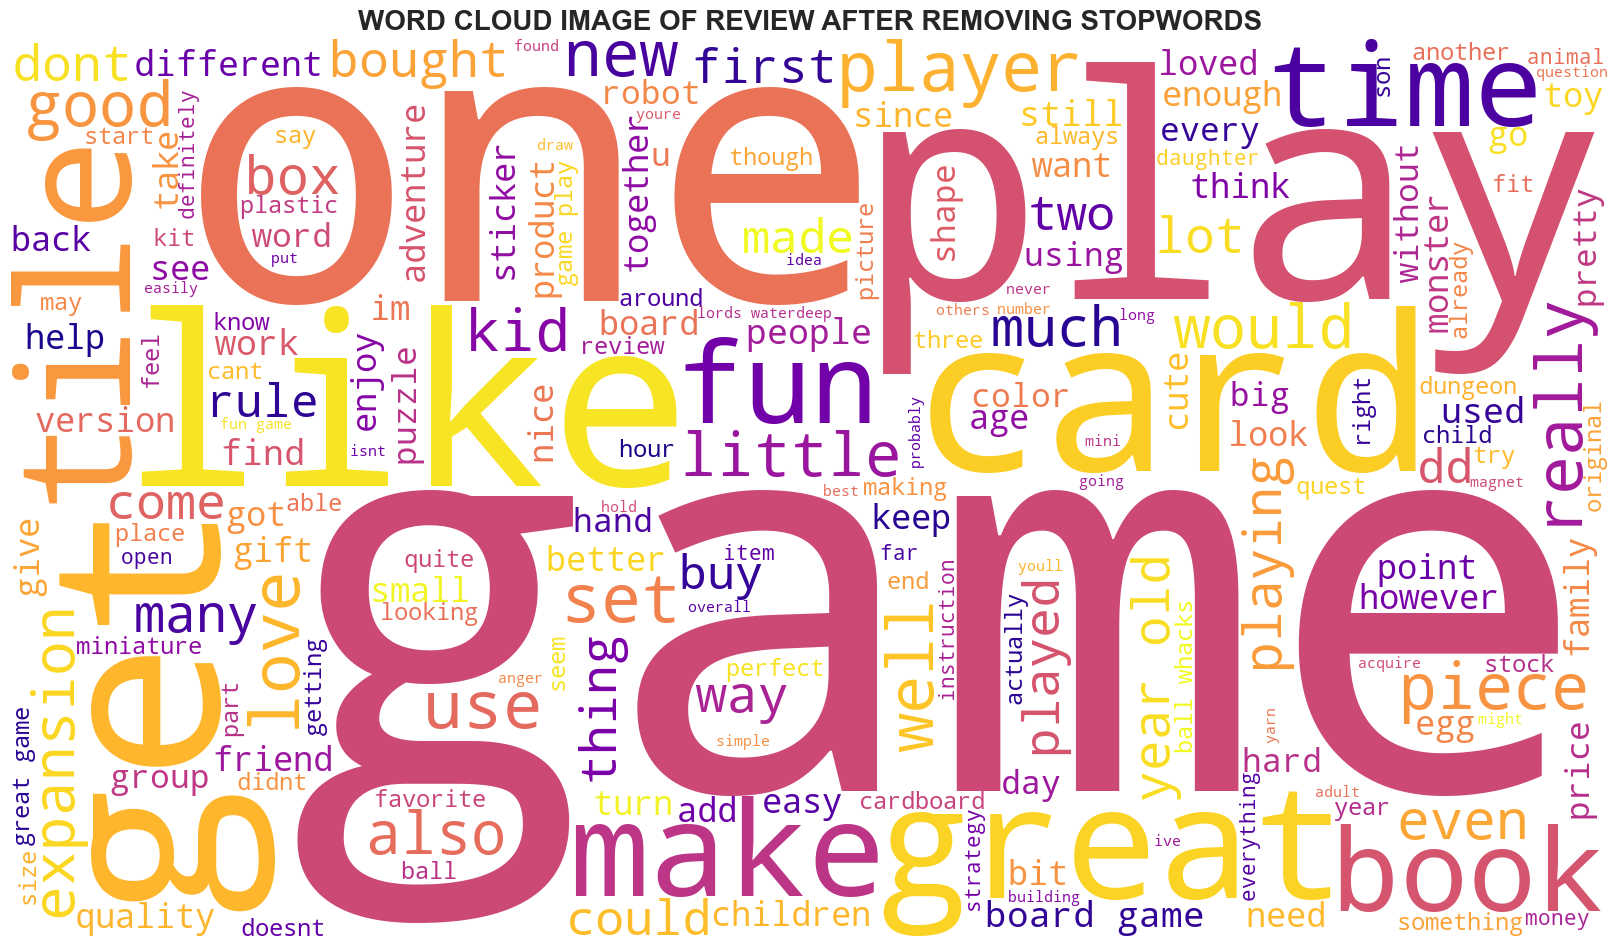

In [107]:
plt.figure(figsize = (16,9), facecolor = None)
plt.imshow(word_cloudrt)
plt.axis('off')
plt.tight_layout(pad = 0)
plt.title('WORD CLOUD IMAGE OF REVIEW AFTER REMOVING STOPWORDS', fontsize = 20, fontweight = 'bold')
plt.savefig("wc rev.png", dpi = 300 , bbox_inches = "tight")
plt.show()

In [110]:
# CALCULATE THE FREQUENCY DISTRIBUTION.

fdist2 = FreqDist(tokens_r2)
fdist2

FreqDist({'game': 1359, 'one': 475, 'play': 442, 'fun': 407, 'great': 391, 'like': 373, 'get': 293, 'cards': 281, 'tiles': 280, 'really': 278, ...})

In [111]:
# DETERMINE THE 15 MOST COMMON WORDS IN REVIEW.

counts = pd.DataFrame(Counter(tokens_r2).most_common(15),\
                             columns = ['Word' , 'Frequency']).set_index('Word')

In [112]:
counts

,Frequency
Word,
game,1359
one,475
play,442
fun,407
great,391
like,373
get,293
cards,281
tiles,280


In [113]:
# DEFINE AN EMPTY LIST OF TOKENS FOR SUMMARY.

all_summary_tokens = []
for i in range(tr_dup_cleans.shape[0]):
    all_summary_tokens = all_summary_tokens + tr_dup_cleans['summary_tokens'][i]

In [114]:
# Calculate the Frequency Distribution.

fdist = FreqDist(all_summary_tokens)
fdist

FreqDist({'game': 268, 'the': 257, 'a': 238, 'great': 236, 'for': 229, 'to': 192, 'fun': 175, 'and': 168, 'it': 139, 'of': 131, ...})

In [115]:
# REMOVE ALPHANUMERIC

tokens_s = [word for word in all_summary_tokens if word.isalnum()]

In [116]:
# REMOVE STOPWORDS.

nltk.download('stopwords')
from nltk.corpus import stopwords
english_stopwords = set(stopwords.words('english'))
tokens_s2 = [x for x in tokens_s if x.lower() not in english_stopwords]
tokens_s2_string = ''
for value in tokens_s2:
    tokens_s2_string = tokens_s2_string + value + ' '
    

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Babisha\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [117]:
# PLOT THE WORDCLOUD IMAGE OF SUMMARY AFTER REMOVING STOPWORDS.

word_cloudst = WordCloud(width = 1600 , height = 900,\
                        background_color = 'white',\
                        colormap = 'plasma',\
                        stopwords = 'none',\
                         min_font_size = 10).generate(tokens_s2_string)

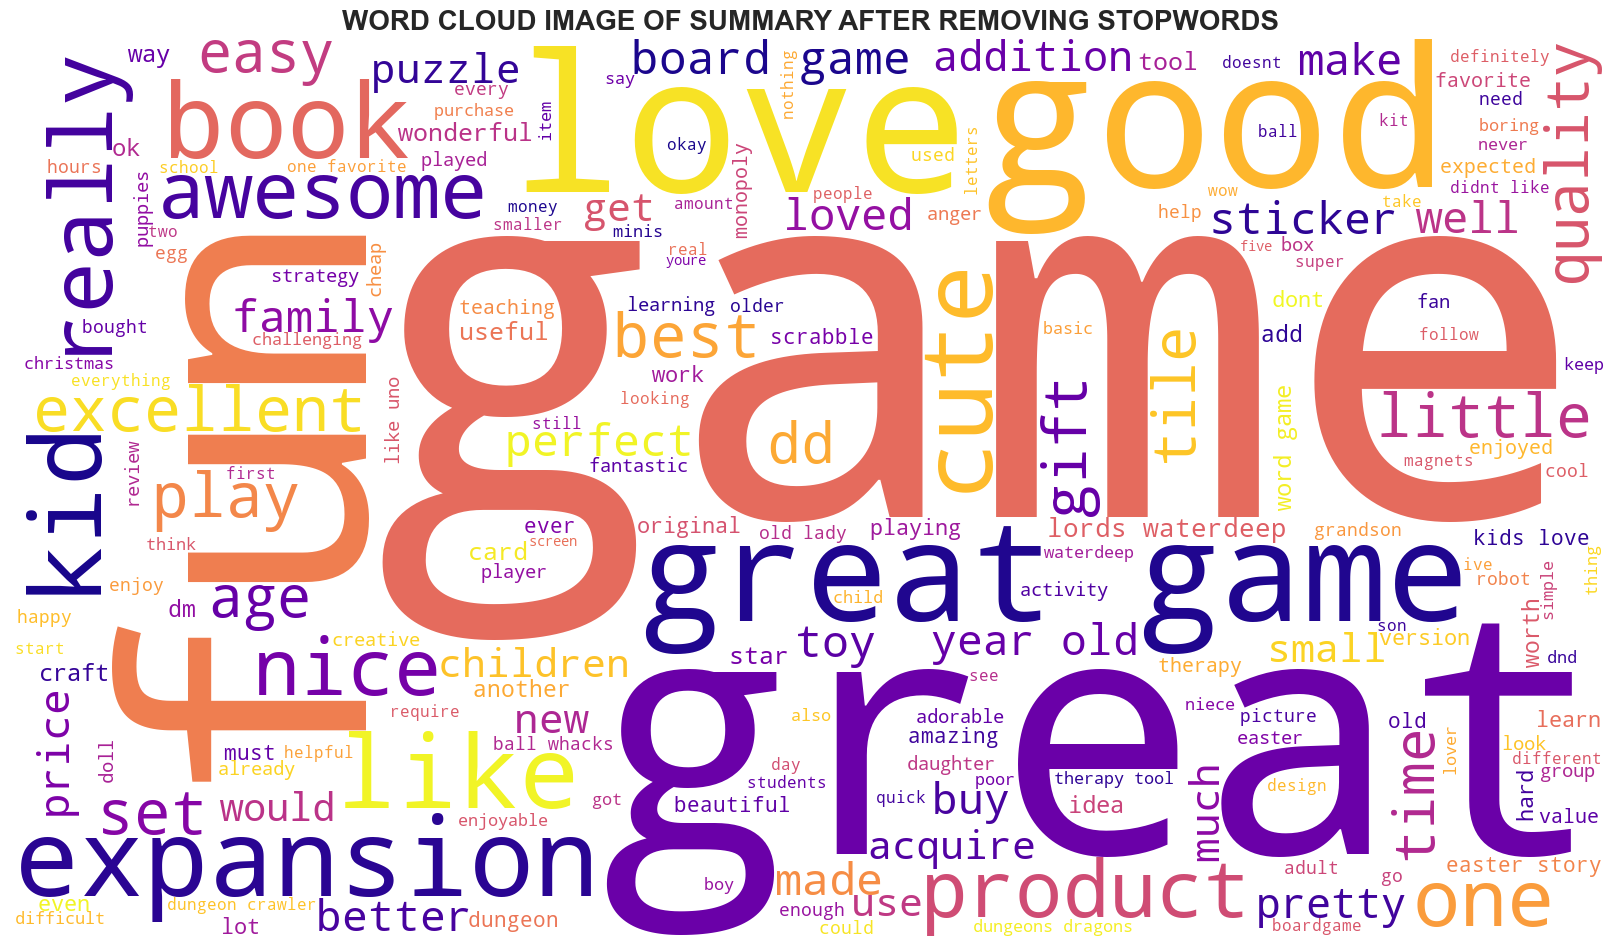

In [118]:
plt.figure(figsize = (16,9), facecolor = None)
plt.imshow(word_cloudst)
plt.axis('off')
plt.tight_layout(pad = 0)
plt.title('WORD CLOUD IMAGE OF SUMMARY AFTER REMOVING STOPWORDS', fontsize = 20, fontweight = 'bold')
plt.savefig("wc sum.png", dpi = 300 , bbox_inches = "tight")
plt.show()

In [119]:
# DETERMINE THE FREQUENCY DISTRIBUTION.

fdist2 = FreqDist(tokens_s2)
fdist2

FreqDist({'game': 268, 'great': 236, 'fun': 175, 'good': 84, 'love': 70, 'like': 54, 'kids': 48, 'book': 42, 'expansion': 42, 'cute': 40, ...})

In [120]:
# DETERMINE THE 15 MOST COMMON WORDS IN SUMMARY.

counts1 = pd.DataFrame(Counter(tokens_s2).most_common(15),\
                             columns = ['Word' , 'Frequency']).set_index('Word')

In [121]:
counts1

,Frequency
Word,
game,268
great,236
fun,175
good,84
love,70
like,54
kids,48
book,42
expansion,42


### ***EXTRACT POLARITY AND SUBJECTIVITY FROM REVIEW.***

In [122]:
# CALCULATE SENTIMENT POLARITY SCORE FOR REVIEW.

def generate_polarity(comment):
    return TextBlob(comment).sentiment[0]

In [123]:
tr_dup_cleans['polarity_r'] = tr_dup_cleans['review'].apply(generate_polarity)

C:\Users\Babisha\AppData\Local\Temp\ipykernel_23712\1592061472.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  tr_dup_cleans['polarity_r'] = tr_dup_cleans['review'].apply(generate_polarity)


In [125]:
tr_dup_cleans['polarity_r'].head()

0   -0.036111
1    0.035952
2    0.116640
3    0.578788
4   -0.316667
Name: polarity_r, dtype: float64

In [126]:
# CALCULATE SUBJECTIVITY SCORE FOR REVIEW.

def generate_subjectivity(comment):
    return TextBlob(comment).sentiment[0]

In [127]:
tr_dup_cleans['subjectivity'] = tr_dup_cleans['review'].apply(generate_subjectivity)

C:\Users\Babisha\AppData\Local\Temp\ipykernel_23712\3776743927.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  tr_dup_cleans['subjectivity'] = tr_dup_cleans['review'].apply(generate_subjectivity)


In [128]:
tr_dup_cleans['subjectivity'].head()

0   -0.036111
1    0.035952
2    0.116640
3    0.578788
4   -0.316667
Name: subjectivity, dtype: float64

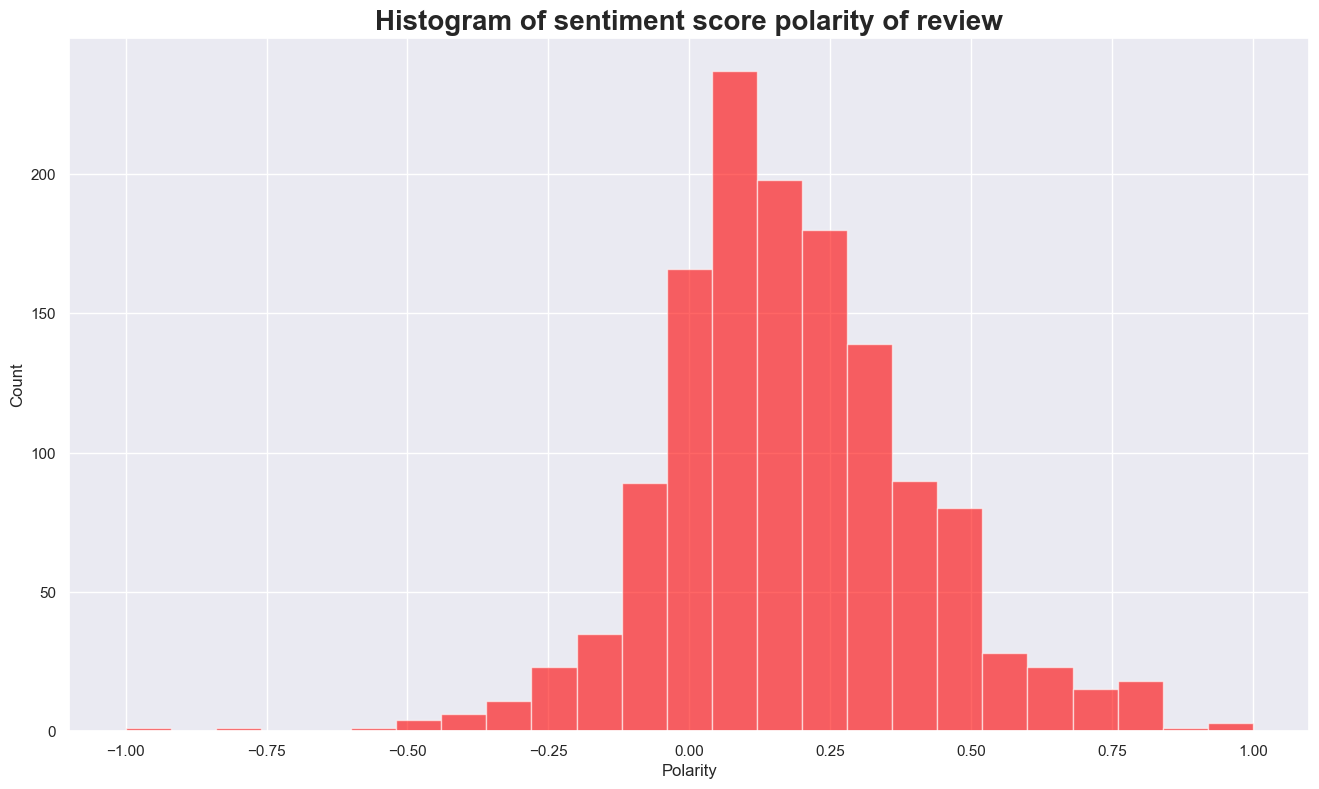

In [129]:
# PLOT THE HISTOGRAM OF POLARITY OF REVIEW.

num_bins = 25
plt.figure(figsize=(16,9))
n, bins, patches = plt.hist(tr_dup_cleans['polarity_r'], num_bins, facecolor = 'red',alpha = 0.6)
plt.xlabel('Polarity', fontsize = 12)
plt.ylabel('Count', fontsize =12)
plt.title('Histogram of sentiment score polarity of review', fontsize=20, fontweight = 'bold')
plt.savefig("hist sent sc.png", dpi = 300 , bbox_inches = "tight")
plt.show()

### ***EXTRACT POLARITY AND SUBJECTIVITY FROM REVIEW.***

In [130]:
# CALCULATE SENTIMENT POLARITY SCORE FOR SUMMARY.

def generate_polarity(comment):
    return TextBlob(comment).sentiment[0]

In [131]:
tr_dup_cleans['polarity_s'] = tr_dup_cleans['summary'].apply(generate_polarity)

C:\Users\Babisha\AppData\Local\Temp\ipykernel_23712\2778214382.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  tr_dup_cleans['polarity_s'] = tr_dup_cleans['summary'].apply(generate_polarity)


In [132]:
tr_dup_cleans['polarity_s'].head()

0    0.15
1   -0.80
2    0.00
3    0.00
4    0.00
Name: polarity_s, dtype: float64

In [133]:
# CALCULATE SUBJECTIVITY SCORE FOR SUMMARY.

def generate_subjectivity(comment):
    return TextBlob(comment).sentiment[0]

In [134]:
tr_dup_cleans['subjectivity'] = tr_dup_cleans['summary'].apply(generate_subjectivity)

C:\Users\Babisha\AppData\Local\Temp\ipykernel_23712\2055397233.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  tr_dup_cleans['subjectivity'] = tr_dup_cleans['summary'].apply(generate_subjectivity)


In [135]:
tr_dup_cleans['subjectivity'].head()

0    0.15
1   -0.80
2    0.00
3    0.00
4    0.00
Name: subjectivity, dtype: float64

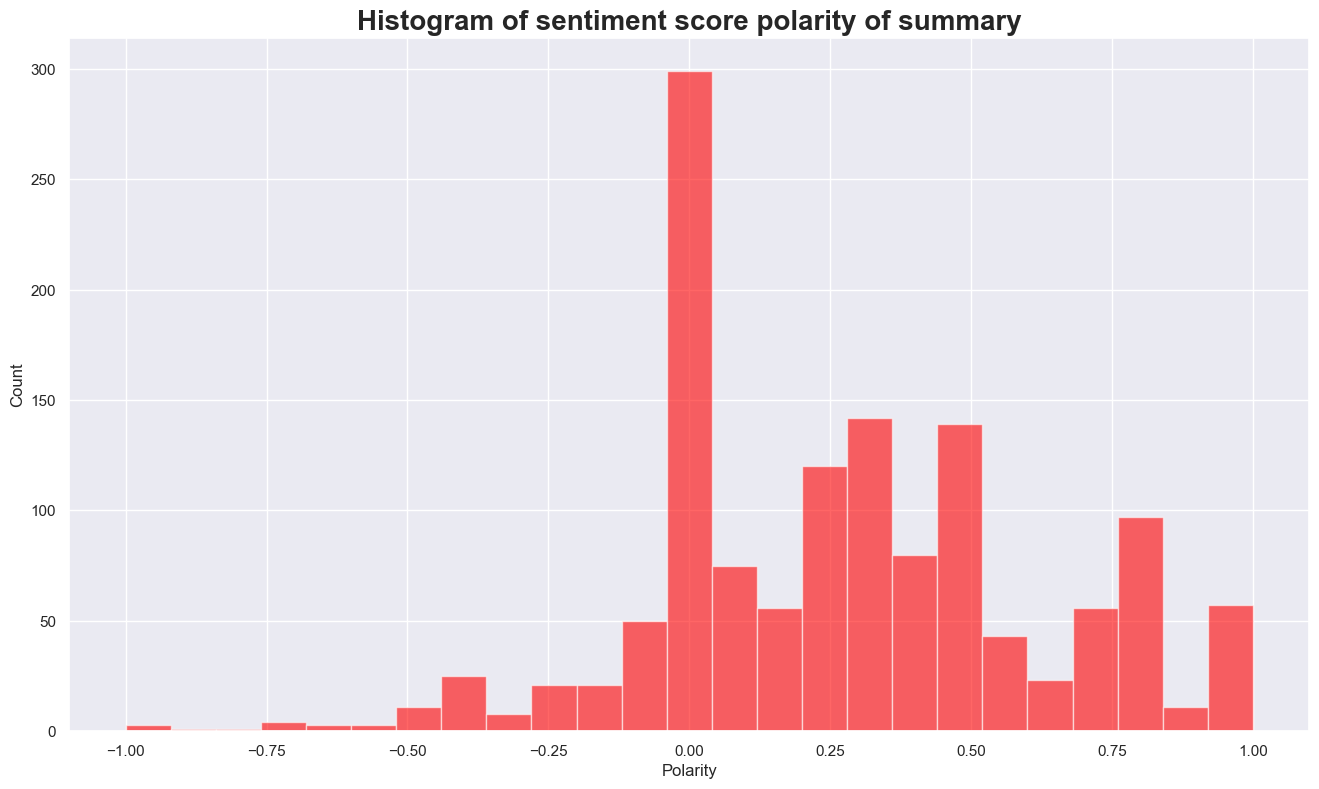

In [136]:
# PLOT THE HISTOGRAM OF POLARITY OF SUMMARY.

num_bins = 25
plt.figure(figsize=(16,9))
n, bins, patches = plt.hist(tr_dup_cleans['polarity_s'], num_bins, facecolor = 'red',alpha = 0.6)
plt.xlabel('Polarity', fontsize = 12)
plt.ylabel('Count', fontsize =12)
plt.title('Histogram of sentiment score polarity of summary', fontsize=20, fontweight = 'bold')
plt.savefig("hist sc pol sum.png", dpi = 300 , bbox_inches = "tight")
plt.show()

### ***IDENTIFY TOP 20 POSITIVE AND NEGATIVE REVIEWS AND SUMMARIES RESPECTIVELY***

In [137]:
#TOP 20 POSITIVE REVIEWS

tr_dup_cleans.shape

(1349, 9)

In [141]:
tr_dup_cleans_na = tr_dup_cleans[tr_dup_cleans.isna().any(axis=1)]
tr_dup_cleans_na.shape

(0, 9)

In [144]:
positive_sentiment_r = tr_dup_cleans.nlargest(20, 'polarity_r')

In [146]:
positive_sentiment_r =positive_sentiment_r[['review', 'polarity_r', 'subjectivity']].reset_index()

In [147]:
positive_sentiment_r.style.set_properties(subset = ['review'], **{'width': '1200px'})

,index,review,polarity_r,subjectivity
0,564,perfect,1.000000,-0.400000
1,1080,my daughter loves her stickers awesome seller thank you,1.000000,1.000000
2,1334,perfect for tutoring my grandson in spelling,1.000000,0.000000
3,890,the best part i see is the box what a wonderfully diverse and rounded set for the cost i am so happy and as the dm you know that if i am happy my players are happy,0.880000,1.000000
4,498,great quality very cute and perfect for my toddler,0.816667,0.816667
5,31,the pictures are great ive done one and gave it to a friend of mine who likes dragons,0.800000,0.800000
6,336,great seller happy with my purchase 5 starrrr,0.800000,0.800000
7,439,great easter gift for kids,0.800000,0.800000
8,491,these are great,0.800000,0.500000
9,692,bought this because i wanted it all these dd games are great,0.800000,0.800000


In [148]:
# TOP 20 NEGATIVE REVIEWS.

negative_sentiment_r = tr_dup_cleans.nsmallest(20, 'polarity_r')

In [149]:
negative_sentiment_r =negative_sentiment_r[[ 'review', 'polarity_r', 'subjectivity']].reset_index()

In [150]:
negative_sentiment_r.style.set_properties(subset = ['review'], **{'width': '1200px'})

,index,review,polarity_r,subjectivity
0,165,booo unles you are patient know how to measure i didnt have the patience neither did my daughter boring unless you are a craft person which i am not,-1.000000,-1.000000
1,147,incomplete kit very disappointing,-0.780000,0.000000
2,267,one of my staff will be using this game soon so i dont know how well it works as yet but after looking at the cards i believe it will be helpful in getting a conversation started regarding anger and what to do to control it,-0.550000,-0.550000
3,90,i bought this as a christmas gift for my grandson its a sticker book so how can i go wrong with this gift,-0.500000,0.000000
4,141,i sent this product to my granddaughter the pompom maker comes in two parts and is supposed to snap together to create the pompoms however both parts were the same making it unusable if you cant make the pompoms the kit is useless since this was sent as a gift i do not have it to return very disappointed,-0.491667,0.000000
5,251,my 8 yearold granddaughter and i were very frustrated and discouraged attempting this craft it is definitely not for a young child i too had difficulty understanding the directions we were very disappointed,-0.446250,0.000000
6,382,i purchased this on the recommendation of two therapists working with my adopted children the children found it boring and put it down half way through,-0.440741,0.000000
7,312,this game although it appears to be like uno and have an easier play method it was still too time consuming and wordy for my children with learning disabilities,-0.400000,-0.400000
8,355,my son loves playing this game it was recommended by a counselor at school that works with him,-0.400000,0.000000
9,713,if you like me used to play dd but now you and your friends growed up and cant be together because all the responsibilities and bla bla bla this game is for you come to the dungeon,-0.400000,0.000000


In [152]:
# TOP 20 POSITIVE SUMMARIES.

positive_sentiment_s = tr_dup_cleans.nlargest(20, 'polarity_s')

In [153]:
positive_sentiment_s =positive_sentiment_s[['summary', 'polarity_s', 'subjectivity']].reset_index()

In [154]:
positive_sentiment_s.style.set_properties(subset = ['summary'], **{'width': '1200px'})

,index,summary,polarity_s,subjectivity
0,5,best gm screen ever,1.000000,1.000000
1,23,wonderful designs,1.000000,1.000000
2,27,perfect,1.000000,1.000000
3,61,theyre the perfect size to keep in the car or a diaper,1.000000,1.000000
4,107,perfect for preschooler,1.000000,1.000000
5,112,awesome sticker activity for the price,1.000000,1.000000
6,132,awesome book,1.000000,1.000000
7,133,he was very happy with his gift,1.000000,1.000000
8,150,awesome,1.000000,1.000000
9,166,awesome and welldesigned for 9 year olds,1.000000,1.000000


In [155]:
# TOP 20 NEGATIVE REVIEWS.

negative_sentiment_s = tr_dup_cleans.nsmallest(20, 'polarity_s')

In [156]:
negative_sentiment_s =negative_sentiment_s[[ 'summary', 'polarity_s', 'subjectivity']].reset_index()

In [157]:
negative_sentiment_s.style.set_properties(subset = ['summary'], **{'width': '1200px'})

,index,summary,polarity_s,subjectivity
0,17,the worst value ive ever seen,-1.000000,-1.000000
1,165,boring unless you are a craft person which i am,-1.000000,-1.000000
2,587,boring,-1.000000,-1.000000
3,837,before this i hated running any rpg campaign dealing with towns because it,-0.900000,-0.900000
4,1,another worthless dungeon masters screen from galeforce9,-0.800000,-0.800000
5,116,disappointed,-0.750000,-0.750000
6,266,promotes anger instead of teaching calming methods,-0.700000,-0.700000
7,634,too bad this is not what i was expecting,-0.700000,-0.700000
8,637,bad qualityall made of paper,-0.700000,-0.700000
9,144,at age 31 i found these very difficult to make,-0.650000,-0.650000


In [143]:
tr_dup_cleans.head()

,level_0,index,review,summary,review_tokens,summary_tokens,polarity_r,subjectivity,polarity_s
0,0,0,when it comes to a dms screen the space on the...,the fact that 50 of this space is wasted on ar...,"[when, it, comes, to, a, dms, screen, the, spa...","[the, fact, that, 50, of, this, space, is, was...",-0.036111,0.15,0.15
1,1,1,an open letter to galeforce9 your unpainted mi...,another worthless dungeon masters screen from ...,"[an, open, letter, to, galeforce9, your, unpai...","[another, worthless, dungeon, masters, screen,...",0.035952,-0.80,-0.80
2,2,2,nice art nice printing why two panels are fill...,pretty but also pretty useless,"[nice, art, nice, printing, why, two, panels, ...","[pretty, but, also, pretty, useless]",0.116640,0.00,0.00
3,3,3,amazing buy bought it as a gift for our new dm...,five stars,"[amazing, buy, bought, it, as, a, gift, for, o...","[five, stars]",0.578788,0.00,0.00
4,4,4,as my review of gf9s previous screens these we...,money trap,"[as, my, review, of, gf9s, previous, screens, ...","[money, trap]",-0.316667,0.00,0.00
